# Seaborn Temelleri

Bu derste aynı grafikleri daha az kodla, istatistiksel varsayılanlarla ve DataFrame'e doğrudan bağlı biçimde üreten seaborn kütüphanesine geçiyoruz. Histogram, kutu grafiği, çubuk grafiği ve çizgi grafiğini seaborn'la üretecek; `hue` ile kategorileri renklerle ayırmayı ve hazır tema/paletleri kullanmayı öğreneceksin.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- seaborn'un `data`/`x`/`y` arayüzüyle grafik üretmek
- `hue` parametresiyle kategorileri renkle ayırmak
- Histogram + yoğunluk eğrisi (`histplot`, `kde`) ve kutu grafiği (`boxplot`) çizmek
- `barplot` ve `lineplot`'ın otomatik özet (ortalama, güven aralığı) davranışını anlamak
- Tema (`set_theme`) ve palet seçimlerini uygulamak

Bu ders, kursun 7. öğrenme çıktısının seaborn ayağını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

7. derste ciro-adet dağılım grafiğinde üç ayrı çizgi görmüştün ve ipucunda "grupları renklerle ayıracağız" demiştik. matplotlib'te bunu her grup için ayrı `plot` çağrısı ve elle renk listesiyle yaparız (8. dersteki ürün renkleri gibi). seaborn'da ise tek bir `hue="urun"` parametresi bunu yapar: veriyi gruba göre böler, renklendirir ve göstergeyi kurar.

seaborn bir "alternatif" değil, matplotlib'in üzerine kurulmuş bir yüksek katman: arka planda yine matplotlib çalışır, ama istatistiksel grafiklerin ortak ihtiyaçlarını (gruplama, özetleme, gösterge, palet) tek satırda halleder. Doğru soru "hangisi daha iyi?" değil, "hangi iş hangi araçla daha kısa yol" olur.

## 🔗 Ön Bilgi

- [pandas DataFrame](05-Pandas-Dataframe.ipynb) ve [Veri Temizleme](06-Data-Cleaning.ipynb): bu derste her iki veri setimizi de kullanacağız.
- [Matplotlib Temelleri](07-Matplotlib-Basics.ipynb) ve [İleri Düzey](08-Matplotlib-Advanced.ipynb): başlık, eksen, çoklu seri ve stil kavramları; seaborn grafiklerinde de `plt.` komutlarıyla tamamlanır.

## 🔍 Birlikte Keşfedelim

Önce verilerimizi hazırlayalım: 6. dersin anketini aynı temizlik adımlarıyla (o derste gerekçelendirmiştik) hızlıca temizliyoruz ve 5. derstin satış tablosunu yüklüyoruz:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

# Anket: 6. dersteki temizlik adımları (özet)
anket = pd.read_csv("../Data/06-survey-dirty.csv")
anket = anket.drop_duplicates()
anket["sehir"] = anket["sehir"].replace(
    {"istanbul": "İstanbul", "İSTANBUL": "İstanbul", "ANKARA": "Ankara", "izmir": "İzmir"})
anket["memnuniyet"] = pd.to_numeric(anket["memnuniyet"], errors="coerce")
anket["yas"] = anket["yas"].fillna(anket["yas"].median())
anket["haftalik_kahve"] = anket["haftalik_kahve"].fillna(anket["haftalik_kahve"].median())
temiz = anket[(anket["yas"] > 15) & (anket["yas"] < 90) & (anket["haftalik_kahve"] < 30)]

# Satış tablosu
satis = pd.read_csv("../Data/05-coffee-sales.csv")

temiz.head()

,id,sehir,yas,haftalik_kahve,memnuniyet
0,1,İstanbul,34.0,7.0,4.0
1,2,İstanbul,28.0,12.0,5.0
2,3,İstanbul,41.0,3.0,3.0
3,4,İstanbul,35.5,5.0,4.0
4,5,İstanbul,23.0,10.0,5.0


**Tahminin:** Yaş ile haftalık kahve tüketimi arasındaki ilişkiyi, şehirleri de ayırarak görmek istiyoruz. Bunu matplotlib'le yapsaydık her şehir için ayrı bir `scatter` çağrısı gerekirdi (8. dersteki döngü gibi). seaborn'la ne kadar süreceğini tahmin et; sonra aşağıdaki hücreyi çalıştır:

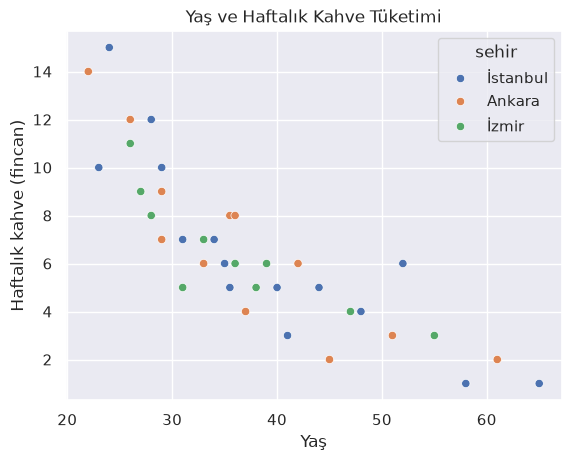

In [2]:
sns.scatterplot(data=temiz, x="yas", y="haftalik_kahve", hue="sehir")
plt.title("Yaş ve Haftalık Kahve Tüketimi")
plt.xlabel("Yaş")
plt.ylabel("Haftalık kahve (fincan)")
plt.show()

**Gözlem:** Tek çağrı; veri `data` ile tabloya bağlandı, `x`/`y` sütun adlarıyla seçildi, `hue="sehir"` şehirleri renklerle ayırdı ve gösterge otomatik kuruldu. Matplotlib'le yaptığımız her şey (başlık, eksen adları) `plt.` komutlarıyla aynen çalışıyor — seaborn katmanı, alttaki matplotlib'i gizlemez, onunla iş birliği yapar.

Veriye bakarsak: yaş ilerledikçe kahve tüketimi hafif düşüyor gibi ve üç şehir iç içe dağılmış; şehir bazında belirgin bir ayrım görünmüyor. İlişki zayıfsa grafiğin dürüstçe göstermesi de budur.

## 📖 Kavramlar

**`data`/`x`/`y` arayüzü:** seaborn fonksiyonları sütun adlarıyla çalışır. `data=temiz` tabloyu, `x="yas"` ve `y="haftalik_kahve"` sütunları adlarıyla verir; ayrıca `values`/`index` taşımaya gerek kalmaz.

**`hue` (renk tonu):** Bir kategorik sütunu renge çevirir ve göstergeyi kurar. seaborn'un en güçlü fikri budur: "hangi kategoriyi ayırmak istiyorsan söyle, gerisini ben yaparım."

**`palette`:** `hue` ile ayrılan kategorilere uygulanacak renk seti. Kategorik paletler (`"Set2"`, `"Dark2"`...) 2. dersin renk rejimleri konusunun uygulamasıdır.

**Otomatik özet davranışı:** `barplot` ve `lineplot`, her kategori için değerleri **otomatik özetler** (varsayılan ortalama) ve etrafına güven aralığı çubuğu/bantı çizer. Aynı x değerinden birden çok gözlem varsa seaborn sizin yerinize özet hesaplar — matplotlib'te bunu `groupby` ile kendimiz yapıyorduk.

**`set_theme`:** seaborn'un görünüm ayarı; ızgara, yazı tipi ve renk döngüsünü tek çağrıda kurar. matplotlib stili gibi kalıcıdır ama okunabilir varsayılanlarıyla gelir.

## 🛠️ Uygulama

### 1) Histogram ve yoğunluk eğrisi

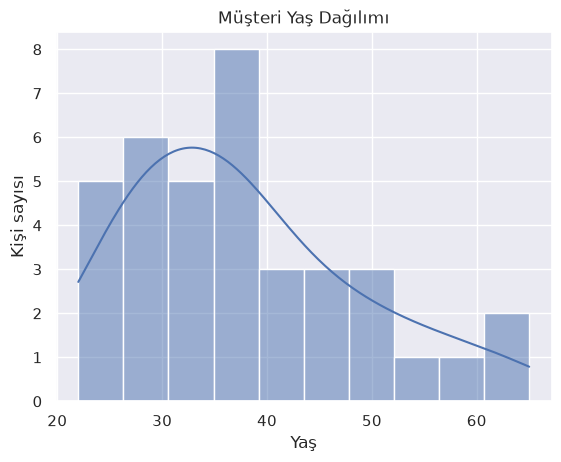

In [3]:
sns.histplot(data=temiz, x="yas", bins=10, kde=True)
plt.title("Müşteri Yaş Dağılımı")
plt.xlabel("Yaş")
plt.ylabel("Kişi sayısı")
plt.show()

`kde=True`, histogramın üzerine dağılımı yumuşatan bir **yoğunluk eğrisi (kernel density estimate)** ekler. Histogram ayrıntı düzeyini `bins` yönetir (7. ders); yoğunluk eğrisi, aralık seçiminden bağımsız bir "dağılımın şekli" okuması sunar.

### 2) Kutu grafiği: dağılım karşılaştırması

2. derste kutu grafiği "medyan, çeyrekler ve aykırı değerler" demiştik; şimdi üretelim. Şehir bazında haftalık tüketim dağılımı:

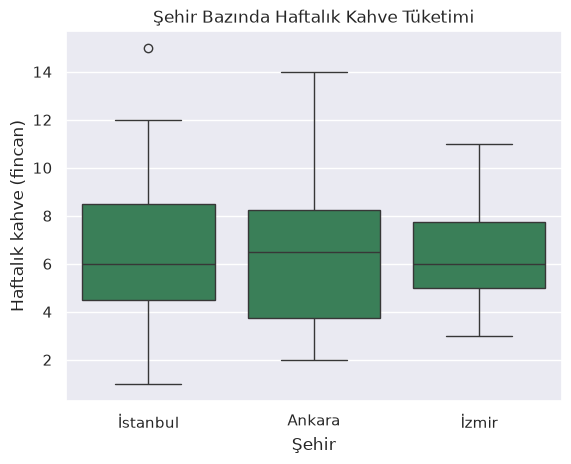

In [4]:
sns.boxplot(data=temiz, x="sehir", y="haftalik_kahve", color="seagreen")
plt.title("Şehir Bazında Haftalık Kahve Tüketimi")
plt.xlabel("Şehir")
plt.ylabel("Haftalık kahve (fincan)")
plt.show()

Kutunun ortasındaki çizgi **medyan**, kutunun kenarları çeyrekler, bıyıklar tipik aralık, tekli noktalar aykırılardır. Üç şehrin medyanları birbirine yakın; kutu yükseklikleri (yayılım) de benzer. 6. derste sayılarla yaptığımız dağılım karşılaştırmasını artık gözle yapıyoruz.

### 3) Çubuk grafik: otomatik özet

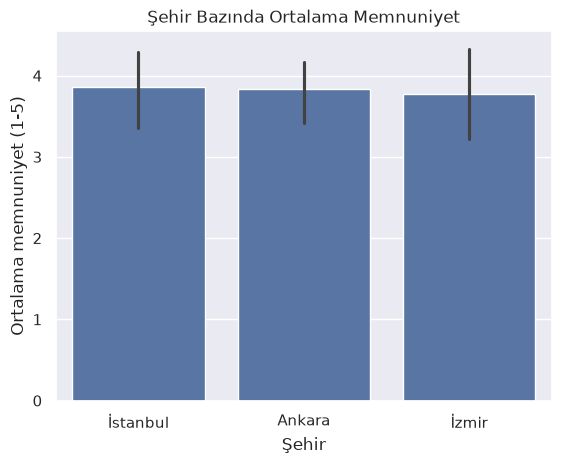

In [5]:
sns.barplot(data=temiz, x="sehir", y="memnuniyet")
plt.title("Şehir Bazında Ortalama Memnuniyet")
plt.xlabel("Şehir")
plt.ylabel("Ortalama memnuniyet (1-5)")
plt.show()

Dikkat: `memnuniyet` sütunu her şehirde çok sayıda satır taşıyor ve seaborn her şehir için **ortalamayı kendisi hesapladı**. Çubukların üstündeki ince dikey çizgiler **güven aralığıdır**: "gerçek ortalama büyük olasılıkla bu aradadır" demenin yolu. Aralığı dar olan şehirde tahmin daha kesindir. Matplotlib'te bu özet için `groupby` + `plt.bar` yazardık; seaborn üç işi tek çağrıda birleştirdi.

### 4) Çizgi grafiği: özet + güven bandı

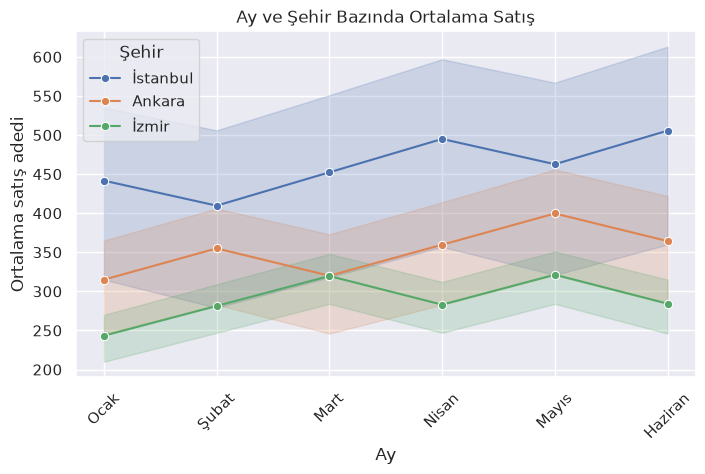

In [6]:
plt.figure(figsize=(8, 4.5))
sns.lineplot(data=satis, x="ay", y="adet", hue="sehir", marker="o")
plt.title("Ay ve Şehir Bazında Ortalama Satış")
plt.xlabel("Ay")
plt.ylabel("Ortalama satış adedi")
plt.xticks(rotation=45)
plt.legend(title="Şehir")
plt.show()

Buradaki numara fark et: satış tablosunda her ay-şehir birleşimi **üç ürün** için ayrı satır taşıyor. seaborn her noktada ortalama alıp etrafına güven bandı çizdi; bant, üç ürünün birbirinden ne kadar ayrıştığını gösteriyor. `hue="sehir"` yine şehirleri renklerle ayırdı ve göstergeye `title` verdik.

### 5) Palet ve tema

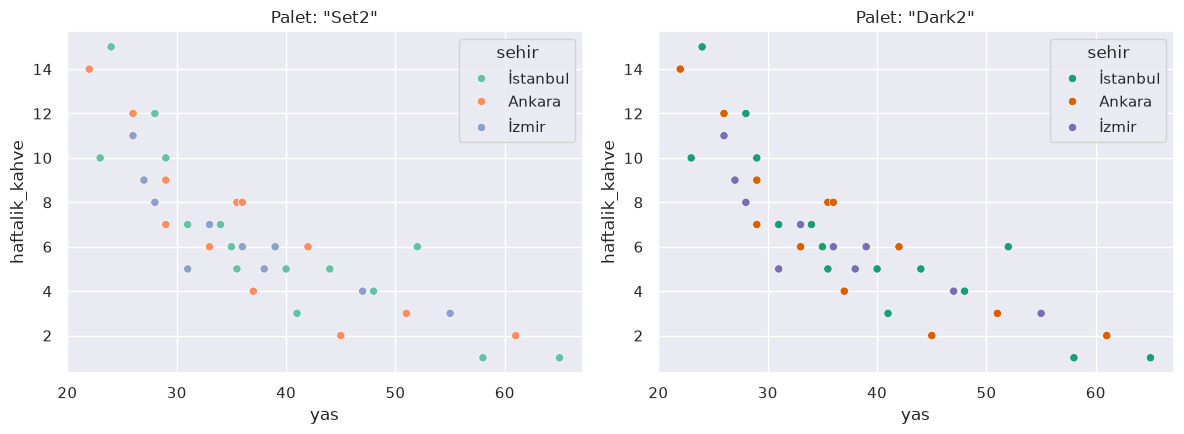

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(data=temiz, x="yas", y="haftalik_kahve",
                hue="sehir", palette="Set2", ax=ax1)
ax1.set_title('Palet: "Set2"')

sns.scatterplot(data=temiz, x="yas", y="haftalik_kahve",
                hue="sehir", palette="Dark2", ax=ax2)
ax2.set_title('Palet: "Dark2"')

plt.tight_layout()
plt.show()

Palet, kategorik ayrımın "karakterini" değiştirir ama mesajı değiştirmez. Seçimini 2. dersin ilkelerine göre yap: net ayrışma (renk körlüğü dostu tonlar), gereksiz parlaklık yok.

### 6) Kodu tamamla (TODO)

In [8]:
# TODO: temiz tablosuyla seaborn.boxplot çiz:
# x="sehir", y="memnuniyet" — şehir bazında memnuniyet dağılımı.
# Başlık ve eksen etiketlerini de ekle.

# sns.boxplot(...)
# plt.title(...)
# plt.show()

print("Kontrol: genel ortalama memnuniyet:", round(temiz['memnuniyet'].mean(), 2))

Kontrol: genel ortalama memnuniyet: 3.83


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** `hue`'suş scatter ile `hue`'lu scatter'ın farkını kendin gör: yukarıdaki scatter'ı `hue="sehir"` olmadan çiz. Noktaların "tek yumru" mu yoksa örüntülü mü göründüğüne bak; renk, gözün gruplamayı yapmasını sağlıyor muydu?

**Deney 2:** `barplot`'ta özet fonksiyonunu değiştirmek. Ortalama yerine medyan kullanalım:

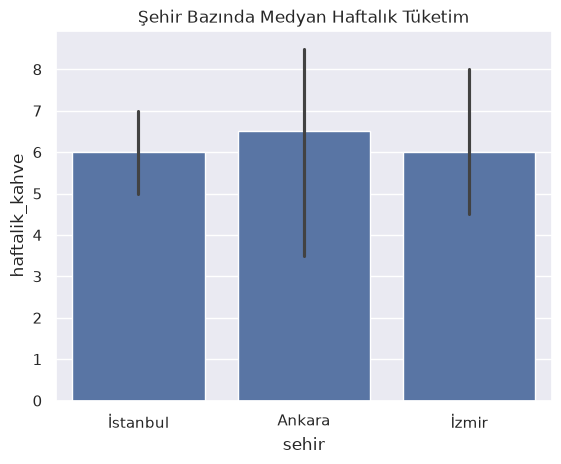

In [9]:
import numpy as np

sns.barplot(data=temiz, x="sehir", y="haftalik_kahve", estimator=np.median)
plt.title("Şehir Bazında Medyan Haftalık Tüketim")
plt.show()

**Gözlem:** Medyan, aykırılara karşı dayanıklıdır (6. ders). `estimator` parametresi hangi özetin çizileceğini belirler; güven aralığı çubukları da bu özete göre yeniden hesaplanır.

**Deney 3:** `boxplot`'ta `showfliers=False` dene. Aykırı noktalar kaybolur. Bu iyi mi kötü mü? (6. derste "aykırı değer karar ister" demiştik; onları **gizlemek** değil, anlamak için göstermiştik.) Kararını bir cümleyle yaz.

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `ValueError: Could not interpret value ... for parameter palette` | Palet adı yanlış yazıldı ya da `palette` `hue`'sız verildi | Önce `hue` ekle; palet adını kontrol et (`"Set2"`, `"Dark2"`...) |
| Grafikte her şey tek renk | `hue` unutuldu ya da sütun tek değerli | `hue` sütununda birden fazla kategori olduğundan emin ol (`unique()`) |
| `KeyError: 'yass'` | Sütun adı yanlış | `list(df.columns)` ile gerçek adlara bak |
| Çizgi grafiğinde bantlar "kalın" görünüyor | Her noktada az gözlem var; bant geniş | Gözlem sayısını artır ya da bantın anlamını (belirsizlik) yorumla |
| seaborn grafiği "farklı" görünüyor | `set_theme` kalıcı | İstediğin temayı yeniden uygula ya da çekirdeği yeniden başlat |

> **İpucu:** seaborn fonksiyonları çoğunlukla `ax` kabul eder: `sns.scatterplot(..., ax=ax1)`. Çoklu panelde `subplots` ile panelleri kur, seaborn grafiklerini panele yönlendir — 8. dersin pano bilgisiyle birleşir.

## 🏋️ Kendin Dene

1. **Anket:** `sns.histplot` ile `haftalik_kahve` dağılımını çiz (`kde=True`); sonra `hue="sehir"` ekleyerek üç dağılımı üst üste gör. Şehirler farklı mı?
2. **Satış:** `sns.lineplot` ile ürün bazında aylık ortalama `adet` çiz (`hue="urun"`). Filtre Kahve ile Türk Kahvesi'nin bant genişliği farkı ne anlatıyor?
3. **Karar:** Aynı iki grafiği matplotlib'le (8. dersin döngü yöntemiyle) yeniden üretmeye çalış. Hangi araç hangi durumda daha kısa yol? Deneyimini iki-üç cümleyle not et.

<details>
<summary>İpucu</summary>

Ürün bazında lineplot'ta her ay-ürün birleşimi üç şehirden üç satır taşır; bantlar bu üç şehrin ayrışmasını gösterir. Bant dar = şehirler benzer; bant geniş = şehirler farklı.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. seaborn'u "matplotlib'in üzerine kurulmuş yüksek katman" olarak tanımladık. Bu cümleyi, arka planda ne olduğunu bilerek kendi cümlelerinle açıkla.
2. `sns.scatterplot(data=temiz, x="yas", y="haftalik_kahve", hue="sehir")` çağrısındaki üç parametre (`data`, `x`/`y`, `hue`) sırasıyla neyi belirtir?
3. `barplot`'taki dikey ince çizgiler nedir ve dar olması ne anlatır?
4. `lineplot` hücresinde bantlar neden oluştu? Satış tablosunda her ay-şehir için kaç satır vardı?
5. `kde=True` ne ekler; histogramdan farklı olarak ne sunar?
6. Aynı grafiği seaborn'la tek satırda, matplotlib'le üç çağrıyla çizdin. "Hangi araç?" kararını verirken hangi ölçütü kullanırsın?

## 🚀 Bağımsız Çalışma

- **Galeri turu:** seaborn örnek galerisini (seaborn.pydata.org/examples/index.html) gez; `violinplot` ve `countplot` gibi henüz görmediğin iki fonksiyonun örneğini kendi verimizle dene.
- **Palet karakteri:** Aynı grafiği üç farklı kategorik paletle çiz (ör. `"Set2"`, `"Dark2"`, `"Paired"`). Hangisi gözün için en rahat ayrışan? Not et; 15. dersteki sunumunda kullanacaksın.

## 📚 Daha Fazlasını Öğrenmek

- seaborn eğitimi: https://seaborn.pydata.org/tutorial.html
- seaborn örnek galerisi: https://seaborn.pydata.org/examples/index.html

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- seaborn, DataFrame sütun adlarıyla çalışan istatistiksel bir üst katmandır; arka planda matplotlib çalışır.
- `data` + `x`/`y` + `hue` üçlüsü, gruplu grafiklerin standart reçetesidir.
- `histplot(kde=True)`, `boxplot`, `scatterplot` dağılım ve ilişki grafiklerini tek çağrıyla üretir.
- `barplot` ve `lineplot` otomatik özetler (varsayılan ortalama) ve güven aralığı gösterir; `estimator` ile özet değişir.
- Palet (`palette`) kategorik ayrımın karakterini, tema (`set_theme`) genel görünümü belirler.
- Araç seçimi kod uzunluğu, istatistiksel varsayılanlar ve okunabilirlik ölçütüyle yapılır.

Sıradaki derste seaborn'un ileri fonksiyonlarıyla çok değişkenli keşif yapıyoruz: ısı haritaları, pairplot ve facet'ler.

---

[← Önceki ders: Matplotlib İleri Düzey](08-Matplotlib-Advanced.ipynb) · [Sıradaki ders: Seaborn İleri Düzey →](10-Seaborn-Advanced.ipynb)

## Cevaplar

<details>
<summary>Uygulama 6: memnuniyet kutu grafiği (TODO çözümü)</summary>

```python
sns.boxplot(data=temiz, x="sehir", y="memnuniyet", color="seagreen")
plt.title("Şehir Bazında Memnuniyet Dağılımı")
plt.xlabel("Şehir")
plt.ylabel("Memnuniyet (1-5)")
plt.show()
```

</details>

<details>
<summary>Kontrol Et 1</summary>

seaborn kendi çizim motoruna sahip değildir; çağrılar sonunda matplotlib grafikleri üretilir. seaborn'un katkısı, istatistiksel grafiklerin ortak işlerini (gruplama, özetleme, gösterge, palet) DataFrame'e doğrudan bağlanan kısa çağrılara indirmesidir. Bu yüzden seaborn grafiği, matplotlib komutlarıyla (başlık, eksen, `savefig`) sorunsuz tamamlanır.

</details>

<details>
<summary>Kontrol Et 2</summary>

`data=temiz` verinin hangi tablo olduğunu; `x` ve `y` hangi sütunların hangi eksene geleceğini; `hue="sehir"` ise şehir kategorisinin renkle ayrılıp göstergeye taşınacağını belirtir.

</details>

<details>
<summary>Kontrol Et 3</summary>

Güven aralığı çizgisidir: gerçek ortalamanın büyük olasılıkla içinde bulunduğu aralığı gösterir. Dar çizgi, tahminin (ve eldeki gözlem sayısının) kesin olduğunu anlatır.

</details>

<details>
<summary>Kontrol Et 4</summary>

Satış tablosunda her ay-şehir birleşimi üç ürün için üç satır taşıyordu (54 satır = 6 ay × 3 şehir × 3 ürün). seaborn her noktada üç değerin ortalamasını çizip etrafına güven bandı kurdu; bant, üç değerin ayrışmasından doğdu.

</details>

<details>
<summary>Kontrol Et 5</summary>

Yoğunluk eğrisi ekler: dağılımın yumuşatılmış, aralık seçiminden bağımsız şeklini çizer. Histogram "aralık sayıları" verir; eğri, dağılımın genel siluetini (çan, çarpıklık, tepe sayısı) gösterir.

</details>

<details>
<summary>Kontrol Et 6</summary>

Ölçüt: aynı işi hangi araç daha az kodla ve daha az hata olasılığıyla yapıyor? Gruplama, özet ve gösterge gerektiren işlerde seaborn kısa yoldur; ince, özel yerleşim ve tam kontrol gerektiren işlerde (8. dersin panoları gibi) matplotlib'in açık arayüzü daha uygundur.

</details>